In [1]:


from rocketpy import Environment, SolidMotor, Rocket, Flight
from rocketpy.sensors import Accelerometer, Gyroscope, Barometer, GnssReceiver
import datetime
import matplotlib.pyplot as plt

import pandas as pd
import numpy as np

In [2]:
lat_ref = 69.6489
lon_ref = 18.95508
alt_ref = 0.0

env = Environment(
    latitude=lat_ref,
    longitude=lon_ref,
    elevation=alt_ref,
)

tomorrow = datetime.date.today() + datetime.timedelta(days=1)

env.set_date(
    (
        tomorrow.year, 
        tomorrow.month,
        tomorrow.day,
        12
    ) # Tomorrow's date in year, month, day, hour UTC format
)

# env.set_atmospheric_model(type='Forecast', file='GFS')

Pro75M1670 = SolidMotor(
    thrust_source="data/motors/cesaroni/Cesaroni_M1670.eng",
    dry_mass=1.815,
    dry_inertia=(0.125, 0.125, 0.002),
    center_of_dry_mass_position=0.317,
    grains_center_of_mass_position=0.397,
    burn_time=3.9,
    grain_number=5,
    grain_separation=0.005,
    grain_density=1815,
    grain_outer_radius=0.033,
    grain_initial_inner_radius=0.015,
    grain_initial_height=0.12,
    nozzle_radius=0.033,
    throat_radius=0.011,
    interpolation_method="linear",
    nozzle_position=0,
    coordinate_system_orientation="nozzle_to_combustion_chamber",
)
# Pro75M1670 = SolidMotor(
#     thrust_source=5e3,
#     dry_mass=1.815,
#     dry_inertia=(0.125, 0.125, 0.002),
#     center_of_dry_mass_position=0.317,
#     grains_center_of_mass_position=0.397,
#     burn_time=3.9,
#     grain_number=5,
#     grain_separation=0.005,
#     grain_density=1815,
#     grain_outer_radius=0.033,
#     grain_initial_inner_radius=0.015,
#     grain_initial_height=0.12,
#     nozzle_radius=0.033,
#     throat_radius=0.011,
#     interpolation_method="linear",
#     nozzle_position=0,
#     coordinate_system_orientation="nozzle_to_combustion_chamber",
# )

calisto = Rocket(
    radius=0.0635,
    mass=14.426,  # without motor
    inertia=(6.321, 6.321, 0.034),
    power_off_drag="data/rockets/calisto/powerOffDragCurve.csv",
    power_on_drag="data/rockets/calisto/powerOnDragCurve.csv",
    center_of_mass_without_motor=0,
    coordinate_system_orientation="tail_to_nose",
)

buttons = calisto.set_rail_buttons(
    upper_button_position=0.0818,
    lower_button_position=-0.6182,
    angular_position=45,
)

calisto.add_motor(Pro75M1670, position=-1.255)

nose = calisto.add_nose(
    length=0.55829, kind="vonKarman", position=1.278
)

fins = calisto.add_trapezoidal_fins(
    n=4,
    root_chord=0.120,
    tip_chord=0.040,
    span=0.100,
    sweep_length=None,
    cant_angle=0,
    position=-1.04956,
)

tail = calisto.add_tail(
    top_radius=0.0635, bottom_radius=0.0435, length=0.060, position=-1.194656
)

# main = calisto.add_parachute(
#     name="main",
#     cd_s=10.0,
#     trigger=800,  # ejection altitude in meters
#     sampling_rate=105,
#     lag=1.5,
#     noise=(0, 8.3, 0.5),
#     radius=1.5,
#     height=1.5,
#     porosity=0.0432,
# )

# drogue = calisto.add_parachute(
#     name="drogue",
#     cd_s=1.0,
#     trigger="apogee",  # ejection at apogee
#     sampling_rate=105,
#     lag=2.5,
#     noise=(0, 8.3, 0.5),
#     radius=1.5,
#     height=1.5,
#     porosity=0.0432,
# )

# Add the drogue parachute to your rocket instance
# drogue = calisto.add_parachute(
#     name="Drogue",
#     cd_s=0.5,                  # Adjust based on your drogue size (Cd * S in m^2)
#     trigger="apogee",
#     sampling_rate=105,         # Sensor frequency in Hz
#     lag=1.5,                   # Deployment and inflation lag in seconds
#     noise=(0, 8.3, 0.5)        # Pressure noise parameters
# )


imu_accel = Accelerometer(
    sampling_rate=100,            # Frequency in Hz
    consider_gravity=True,        # Includes 1g vertical acceleration while stationary
    measurement_range=16*9.8,         # Maximum dynamic range in m/s
    noise_density=0.1,          # Add active white noise
    name="Onboard_Accelerometer"
)

imu_gyro = Gyroscope(
    sampling_rate=100,            # Frequency in Hz
    measurement_range=2000,       # Max angular velocity in deg/s
    noise_density=0.005,          
    name="Onboard_Gyroscope"
)

GNSS = GnssReceiver(
    sampling_rate=2.0,
    position_accuracy=10.0,
    altitude_accuracy=10.0,
)

barometer = Barometer(
    sampling_rate = 100.0
    )

calisto.add_sensor(imu_accel, 0.0)
calisto.add_sensor(imu_gyro, 0.0)
calisto.add_sensor(GNSS, 0.0)
calisto.add_sensor(barometer, 0.0)




/home/noah/NEXT/ESKF_shockwave_simulations/.venv/lib/python3.12/site-packages/rocketpy/sensors/sensor.py:129: UserWarning: The Sensor class (and all its subclasses) is still under experimental development. Some features may be changed in future versions, although we will try to keep the changes to a minimum.
  warnings.warn(


In [3]:
test_flight = Flight(
  rocket=calisto, environment=env, rail_length=5.2, inclination=85, heading=0,max_time_step=0.01
)


In [4]:

time_base = test_flight.z.source[:, 0]

ground_truth = pd.DataFrame({
    "t":       time_base,
    # Position
    "x":      test_flight.x.source[:, 1],
    "y":      test_flight.y.source[:, 1],
    "z": test_flight.z.source[:, 1],
    # Velocity
    "vx":    test_flight.vx.source[:, 1],
    "vy":    test_flight.vy.source[:, 1],
    "vz":    test_flight.vz.source[:, 1],
    # Attitude (quaterninos)
    "qw": [test_flight.e0(t) for t in time_base],
    "qx": [test_flight.e1(t) for t in time_base],
    "qy": [test_flight.e2(t) for t in time_base],
    "qz": [test_flight.e3(t) for t in time_base],
    # Attitude (Euler Angles - Heading, Pitch, Roll)
    "roll":      test_flight.phi.source[:, 1],
    "pitch":  test_flight.theta.source[:, 1],
    "yaw":  test_flight.psi.source[:, 1],
})

imu_accel_dict = imu_accel.to_dict()
imu_gyro_dict = imu_gyro.to_dict()
barometer_dict = barometer.to_dict()
GNSS_dict = GNSS.to_dict()


In [5]:
# Save the sensor logs to a CSV file
imu_accel.export_measured_data("accelerometer_data.csv")
imu_gyro.export_measured_data("gyroscope_data.csv")
barometer.export_measured_data("barometer_data.csv")
GNSS.export_measured_data("GNSS_data.csv")

ground_truth.to_csv("ground_truth.csv")


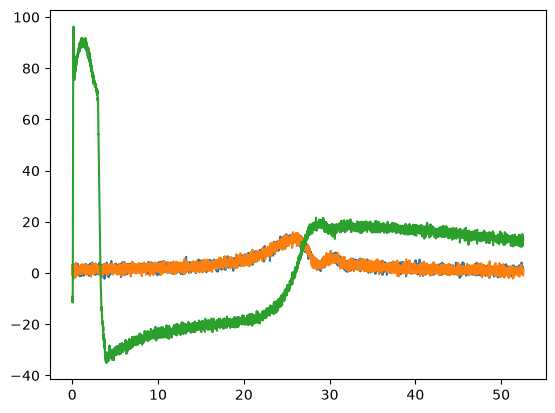

In [6]:

acc = np.array(imu_accel.measured_data)

fig, ax=plt.subplots()

ax.plot(acc[:, 0], acc[:, 1], label="acc x")
ax.plot(acc[:, 0], acc[:, 2], label="acc y")
ax.plot(acc[:, 0], acc[:, 3], label="acc z")


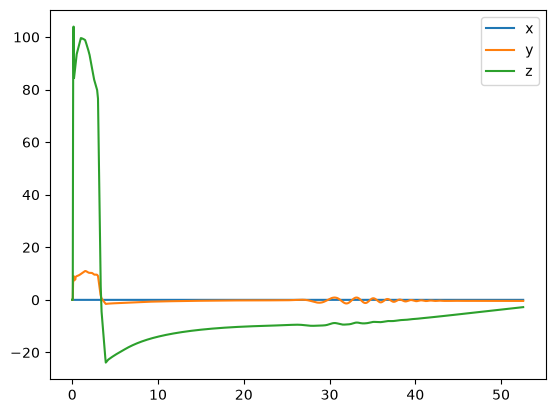

In [7]:

ax = test_flight.ax.source[:, 1]
ay = test_flight.ay.source[:, 1]
az = test_flight.az.source[:, 1]

fig, axs=plt.subplots()
axs.plot(time_base, ax, label="x")
axs.plot(time_base, ay, label="y")
axs.plot(time_base, az, label="z")
axs.legend()